Kod do tworzenia rysunków i pobierania danych jest w pliku `spolecznosci_pomocnicze.py`, który powinien leżeć obok notatnika. 

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

from spolecznosci_pomocnicze import (
    graf_autorow, rysuj_graf_dwudzielny, rysuj_projekcje,
    wczytaj_retweety, rysuj_rdzen,
    wczytaj_kontakty_szkolne, rysuj_klasy_i_spolecznosci, rysuj_tabele_klas,
)

## Rdzenie politycznych retweetów

Dane z pracy Conovera i współautorów [Political Polarization on Twitter](https://zenodo.org/records/4589065) obejmują sześć tygodni przed wyborami do Kongresu USA w 2010 roku. Wierzchołki oznaczają konta, a interakcje - retweety.

**Nasz model:** pomijamy kierunki i pętle, a wszystkie interakcje między daną parą kont zastępujemy jedną krawędzią. Otrzymujemy prosty graf nieskierowany. Etykiety `left/right` pochodzą z danych, nie są wynikiem rozkładu na rdzenie.

Pierwsze uruchomienie pobiera około 11,5 MB do lokalnego folderu `dane`; następne korzystają z kopii. Dane można też pobrać ręcznie z [tej strony](https://zenodo.org/records/4589065) i umieścić plik `icwsm_polarization.zip` w folderze `dane` obok pliku pomocniczego.

In [2]:
G = wczytaj_retweety()
print("Wierzchołki:", G.number_of_nodes())
print("Krawędzie:", G.number_of_edges())

Wierzchołki: 18470
Krawędzie: 48053


**Zadanie 1.** Zbadaj rozkład grafu retweetów `G` na rdzenie.

1. Wyznacz kolejne $k$-rdzenie, zaczynając od $k=0$, aż otrzymasz pierwszy pusty rdzeń. Dla każdego $k$ zapisz liczbę wierzchołków. Podaj największe $k$, dla którego rdzeń jest niepusty.
2. Narysuj niepuste rdzenie za pomocą `rysuj_rdzen`. Przy każdym rysunku podaj wartość $k$.
3. Zrób wykres liczby wierzchołków w $k$-rdzeniu w zależności od $k$. Uwzględnij też pierwszy pusty rdzeń. Między którymi kolejnymi wartościami $k$ odpada najwięcej wierzchołków?

Dodatkowo porównaj zbiory wierzchołków dwóch kolejnych rdzeni. Czym różni się $k$-powłoka od $k$-rdzenia?

**Ściągawka do zadania 1**

- `numery = nx.core_number(G)` — słownik, w którym `numery[v]` to największe $k$, dla którego wierzchołek `v` należy do $k$-rdzenia. `max(numery.values())` daje poziom najgłębszego niepustego rdzenia.
- `H = nx.k_core(G, k=k, core_number=numery)` — wyznacza $k$-rdzeń. Oblicz słownik `numery` raz i używaj go dla kolejnych $k$. `H.number_of_nodes()` lub `len(H)` zwraca liczbę wierzchołków.
- `nx.k_shell(G, k=k, core_number=numery)` — zwraca $k$-powłokę, czyli podgraf na wierzchołkach o numerze rdzenia dokładnie $k$.
- `plt.plot(poziomy, rozmiary, "o-")` — rysuje punkty połączone linią. Listy `poziomy` i `rozmiary` powinny mieć tę samą długość. Osie podpiszesz przez `plt.xlabel("k")` i `plt.ylabel("Liczba wierzchołków")`. Na końcu wywołaj `plt.show()`.

**Rysowanie rdzenia.** Zapisz `fig = rysuj_rdzen(G, H, limit=250)`, dodaj tytuł przez `fig.suptitle(f"{k}-rdzeń")` i wywołaj `plt.show()`. Podaj cały graf `G`, z którego funkcja bierze kolory wierzchołków, oraz obliczony wcześniej rdzeń `H`. Jeśli rdzeń ma więcej wierzchołków niż `limit`, funkcja pokaże fragment złożony z wierzchołków o największych stopniach w `H`. Liczebności do wykresu odczytuj z pełnego `H`.

## Autorzy i artykuły

Rozważmy cztery rzeczywiste prace o społecznościach w sieciach:

- **p1:** [Fast unfolding of communities in large networks](https://arxiv.org/abs/0803.0476);
- **p2:** [Laplacian Dynamics and Multiscale Modular Structure in Networks](https://arxiv.org/abs/0812.1770);
- **p3:** [Stability of graph communities across time scales](https://arxiv.org/abs/0812.1811);
- **p4:** [The stability of a graph partition](https://arxiv.org/abs/1308.1605).

Rozważmy graf dwudzielnny, w którym łączymy autora z pracą, którą napisał. Metadane są zapisane w pliku pomocniczym, więc ten przykład działa offline. 

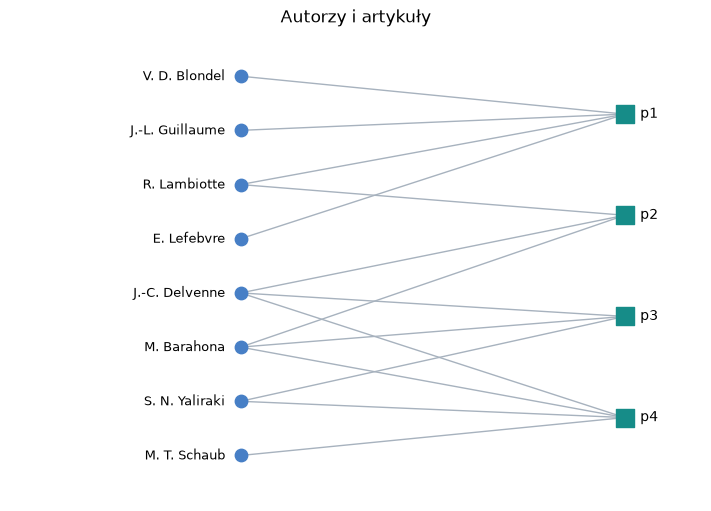

In [3]:
B, autorzy, prace = graf_autorow()
rysuj_graf_dwudzielny(B, autorzy, prace)
plt.show()

**Zadanie 2.** Zbuduj graf współautorstwa (zwany też projekcją na zbiór autorów) i znajdź w nim społeczności za pomocą algorytmu Louvain.

1. Przypomnij sobie zadanie 8 z listy 2. Utwórz macierz sąsiedztwa `A` grafu `B`, umieszczając najpierw autorów, a potem artykuły. Wytnij z niej blok $C$, którego wiersze odpowiadają autorom, a kolumny artykułom.
2. Oblicz $W=CC^\top$ i wyzeruj przekątną. Z macierzy `W` utwórz graf `P`, zachowując nazwy wszystkich autorów. Krawędź łączy dwóch różnych autorów, którzy napisali wspólny artykuł, a jej waga to liczba ich wspólnych artykułów (zamiast myśleć, że krawędzie są ważone, możemy myśleć, że w grafie są krawędzie wielokrotne).
3. Uruchom algorytm Louvain na grafie `P` z uwzględnieniem wag. Podaj liczbę społeczności i wypisz autorów należących do każdej z nich. Narysuj graf używając funkcji `rysuj_projekcje`.

**Ściągawka do zadania 2**

- `nx.to_numpy_array(B, nodelist=autorzy + prace, dtype=int)` tworzy macierz sąsiedztwa w podanej kolejności. Ustal `n = len(autorzy)`. Wyrażenie `A[:n, n:]` wybiera pierwsze `n` wierszy i kolumny od indeksu `n` do końca.
- `C.T` to transpozycja, a `@` oznacza mnożenie macierzy. `np.fill_diagonal(W, 0)` zeruje przekątną `W`, dzięki czemu w projekcji nie będzie pętli.
- `nx.from_numpy_array(W, nodelist=autorzy)` tworzy graf i zapisuje wagi krawędzi w atrybucie `weight`. Wierzchołek odpowiadający wierszowi i kolumnie o indeksie `i` otrzymuje nazwę `autorzy[i]`.
- `grupy = nx.community.louvain_communities(P, weight="weight", seed=7)` uruchamia algorytm Louvain. `seed` pozwala powtórzyć wynik (algorytm Louvain zależy od tego jak uporządkujemy wierzchołki). Każdy element `grupy` to zbiór autorów w jednej społeczności, a `len(grupy)` to liczba społeczności.
- `rysuj_projekcje(B, autorzy, prace, P, grupy)` rysuje graf współautorstwa z kolorami społeczności. Wywołaj potem `plt.show()`.

Aby wypisać nazwy autorów w każdej społeczności, przejdź po grupach w pętli.

```python
for grupa in grupy:
    print(sorted(grupa))
```

## Kontakty w szkole: czy Louvain odtworzy klasy?

W badaniu kontaktów w szkole podstawowej 232 uczniów i 10 nauczycieli nosiło czujniki rejestrujące bliskie kontakty. W pliku `primaryschool.csv.gz` każdy wiersz podaje chwilę $t$ i identyfikatory dwóch osób, które były w kontakcie w ciągu 20 sekund przed $t$. Plik `primaryschool_metadata.txt` przypisuje każdej osobie klasę (np. `3B`) albo etykietę `Teachers`. [Badanie Stehlé i współautorów (2011)](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0023176)

Z danych z pierwszego dnia budujemy nieważony graf nieskierowany `Szkola`. Jego wierzchołkami są wszyscy uczniowie z metadanych, także uczniowie bez krawędzi. Łączymy parę uczniów, jeśli ich kontakty trwały w sumie co najmniej 120 sekund tego dnia. Po zastosowaniu progu każdą krawędź liczymy jednakowo. Atrybut `klasa` przechowuje rzeczywistą klasę ucznia i posłuży do porównania z wynikiem Louvain.

Przy pierwszym uruchomieniu funkcja wczytująca pobiera około 0,5 MB danych do folderu `dane` obok pliku pomocniczego. Oba pliki można też pobrać ręcznie z [Dane SocioPatterns](https://sociopatterns.org/datasets/primary-school-temporal-network-data/) i umieścić w folderze `dane`.

In [6]:
dzien = 0        # 0: pierwszy dzień, 1: drugi dzień.
min_czas = 120   # Minimalny ŁĄCZNY czas kontaktu pary w tym dniu (sekundy).
kontakty = wczytaj_kontakty_szkolne(dzien=dzien, min_czas=min_czas, wazony=False)
uczniowie = {v for v in kontakty if kontakty.nodes[v]["klasa"] != "Teachers"}
Szkola = kontakty.subgraph(uczniowie).copy()
klasy = sorted({Szkola.nodes[v]["klasa"] for v in Szkola})

print("Uczniowie:", len(Szkola))
print("Klasy:", ", ".join(klasy))
print("Krawędzie:", Szkola.number_of_edges())
print("Uczniowie izolowani:", nx.number_of_isolates(Szkola))

Uczniowie: 232
Klasy: 1A, 1B, 2A, 2B, 3A, 3B, 4A, 4B, 5A, 5B
Krawędzie: 1806
Uczniowie izolowani: 6


**Zadanie 3.** Sprawdź, w jakim stopniu społeczności wykryte w sieci kontaktów odpowiadają rzeczywistym klasom.

1. Uruchom Louvain na grafie `Szkola`. Podaj liczbę wykrytych społeczności oraz ich rozmiary.
2. Użyj funkcji `rysuj_klasy_i_spolecznosci` ze ściągawki aby porównać wykryte społeczności z rzeczywistymi klasami.
3. Który podział ma większą modularność?

**Ściągawka do zadania 3**

1. Zapisz wynik poleceniem `spolecznosci = nx.community.louvain_communities(Szkola)`. Każdy element tej listy to zbiór identyfikatorów uczniów z jednej społeczności. `len(spolecznosci)` daje liczbę społeczności. Aby wypisać ich rozmiary, przejdź po liście i dla każdej `grupa` wypisz `len(grupa)`.
2. Wywołaj `rysuj_klasy_i_spolecznosci(Szkola, spolecznosci)`, a potem `plt.show()`. Funkcja bierze rzeczywiste klasy z atrybutu `klasa` w grafie `Szkola` i pokazuje je po lewej. Po prawej koloruje uczniów według listy `spolecznosci`. Pozycje uczniów są takie same na obu rysunkach.
3. Zacznij od pustej listy `podzial_klas = []`. Dla każdej etykiety `klasa` z listy `klasy` utwórz zbiór `{v for v in Szkola if Szkola.nodes[v]["klasa"] == klasa}` i dodaj go do listy przez `append`. Wywołaj `nx.community.modularity(Szkola, podzial_klas)`, a następnie `nx.community.modularity(Szkola, spolecznosci)`.

**Zadanie 3+ (dodatkowe).** Zbuduj i wyświetl macierz „klasa × społeczność” dla grafu `Szkola` i wyniku Louvain z zadania 3. Każdy wiersz odpowiada rzeczywistej klasie, a każda kolumna społeczności Louvain. Element macierzy podaje, ilu uczniów z danej klasy trafiło do danej społeczności. Na przykład `3` w wierszu `2A` i kolumnie `S1` oznacza, że trzech uczniów z klasy `2A` trafiło do pierwszej społeczności.

Sprawdź, czy suma elementów macierzy zgadza się z liczbą uczniów w grafie. Wskaż na podstawie tabeli przykłady klas rozdzielonych między kilka społeczności oraz społeczności obejmujących uczniów z kilku klas.

**Ściągawka do zadania 3+**

- Kolejność wierszy wyznacza lista `klasy` z komórki wczytującej dane. `klasy.index(etykieta)` podaje numer wiersza dla etykiety takiej jak `"2A"`. Kolejność kolumn wyznacza lista `spolecznosci` z zadania 3. Indeks `0` odpowiada `S1`, indeks `1` odpowiada `S2` itd.
- Utwórz `tablica = np.zeros((len(klasy), len(spolecznosci)), dtype=int)`. To macierz liczników. Na początku w każdym polu jest zero.
- Przejdź po społecznościach, a wewnątrz każdej z nich po jej uczniach. `enumerate` daje jednocześnie numer kolumny `j` i zbiór uczniów `grupa`. Dla każdego ucznia `v` odczytaj etykietę klasy z grafu i znajdź numer wiersza `i`.

```python
for j, grupa in enumerate(spolecznosci):
    for v in grupa:
        etykieta = Szkola.nodes[v]["klasa"]
        i = klasy.index(etykieta)
        # Zwiększ licznik w tablica[i, j] o 1.
```

Po uzupełnieniu pętli porównaj sumę liczników `tablica.sum()` z liczbą uczniów `len(Szkola)`. Żeby zobaczyć podpisaną tabelę, wywołaj `rysuj_tabele_klas(tablica, klasy)`, a potem `plt.show()`.